Analyze time-series data from platereader experiments.

## Setup

In [ ]:
try:
    import cdk
    print("CDK already installed, skipping installation and restart.")
except ImportError:
    !pip install nucleus-cdk==0.6.3 -q > /dev/null 2>&1
    print("\nInstallation complete. Restarting runtime to refresh dependencies...")
    import os
    os._exit(0)

CDK already installed, skipping installation and restart.


In [ ]:

import pandas as pd
pd.set_option('display.max_columns', None)
import seaborn as sns
import matplotlib.pyplot as plt

# Import the cdk platereader module
from cdk.instruments import platereader as pr

from cdk import logging
log = logging.setup_logging(logging.ERROR)

## Load Data

In [ ]:
%%writefile drive_utils.py
import os
import re

import gdown


def get_drive_file_id(url):
    """Extract the file ID from a Google Drive share URL."""
    match = re.search(r'/d/([a-zA-Z0-9_-]+)', url)
    if match:
        return match.group(1)
    return None


def download_from_drive(files_info, destination_dir):
    """
    Download files from Google Drive.

    Args:
        files_info (list): List of dicts with 'url' and 'filename'.
        destination_dir (str): Local path to save files.
    Returns:
        dict: Mapping of filenames to local paths.
    """
    os.makedirs(destination_dir, exist_ok=True)

    paths = {}
    for item in files_info:
        url = item['url']
        filename = item['filename']
        dest = os.path.join(destination_dir, filename)
        file_id = get_drive_file_id(url)

        if file_id:
            gdown.download(id=file_id, output=dest, quiet=True)
        else:
            gdown.download(url, output=dest, quiet=True)

        paths[filename] = dest
    return paths

Writing drive_utils.py


In [ ]:
# Set use_drive = True to download data_file and platemap_file from Google Drive instead of
# using local files. Each Drive file must have its permissions set to "Anyone with a link" can "view".
use_drive = True

if use_drive:
    from drive_utils import download_from_drive

    files_to_download = [
        {
            "url": "https://drive.google.com/file/d/1fCIDnSCbRrsiI3w89619i9TKXkkA6Sl-/view?usp=sharing",  # Replace with your data file link.
            "filename": "raw_data.txt",
        },
        {
            "url": "https://drive.google.com/file/d/1t8r2atuNZQvChwyfSsm0ic4uygJrlXHF/view?usp=sharing",  # Replace with your platemap file link.
            "filename": "platemap.csv",
        },
    ]
    downloaded_paths = download_from_drive(files_to_download, destination_dir="data")
    data_file = downloaded_paths["raw_data.txt"]
    platemap_file = downloaded_paths["platemap.csv"]
else:
    data_file = "sample-data/20251111-122213-cytation5-pure-timecourse-gfp-MFG-98-tRNA-QC.txt"
    platemap_file = "sample-data/platemap.csv"

print(f"Data file: {data_file}\nPlatemap file: {platemap_file}")

Data file: data/raw_data.txt
Platemap file: data/platemap.csv


In [ ]:
# Load data
result = pr.load_platereader_data(
    data_file=data_file,
    platemap_file=platemap_file,
    platereader="biotek" # options: "biotek"
)

The output is a list of `PlateReaderResult` objects; if you did more than one read on the plate reader, the results will be in separate objects.

In [ ]:
print(result)

PlateReaderResult with the following 4 blocks:
0: (1752, 55) kinetic read with reads: GFP-G50:485/20,528/20 (Fluorescence) (Plate 'Plate 1')
1: (1752, 55) kinetic read with reads: GFP-G65:485/20,528/20 (Fluorescence) (Plate 'Plate 1')
2: (1752, 55) kinetic read with reads: GFP-G35:485/20,528/20 (Fluorescence) (Plate 'Plate 1')
3: (384, 53) endpoint read with reads: Max V [GFP-G50:485/20,528/20] (Fluorescence), R-Squared [GFP-G50:485/20,528/20] (Fluorescence), t at Max V [GFP-G50:485/20,528/20] (Fluorescence), Lagtime [GFP-G50:485/20,528/20] (Fluorescence), Max V [GFP-G65:485/20,528/20] (Fluorescence), R-Squared [GFP-G65:485/20,528/20] (Fluorescence), t at Max V [GFP-G65:485/20,528/20] (Fluorescence), Lagtime [GFP-G65:485/20,528/20] (Fluorescence), Max V [GFP-G35:485/20,528/20] (Fluorescence), R-Squared [GFP-G35:485/20,528/20] (Fluorescence), t at Max V [GFP-G35:485/20,528/20] (Fluorescence), Lagtime [GFP-G35:485/20,528/20] (Fluorescence), Count (None), Mean (None), Std Dev (None), CV (

Here there were two reads with different gains but the same excitation/emission spectrum, on one plate. If we want just the `GFP-Gext` read, this corresponds to block index 1, so we can extract that block by indexing:

In [ ]:
desired_index = 1
data = result[desired_index]

You can see the underlying data with `data.view()` (which returns a Pandas DataFrame):

In [ ]:
data.view().head()

,Date,Experiment,Well,Name,Type,Time,Data,Read,Read Name,Reader Type,Reader ID,Plate Type,Plate ID,Start Time,Read Modality,Gain,Excitation Wavelength (nm),Excitation Bandwidth (nm),Excitation Optics,Emission Wavelength (nm),Emission Bandwidth (nm),Emission Optics,Read Geometry,Read Height (mm),Rxn Volume (uL),Condition,[DNA] (nM),[TetR] (nM),[ATC] (uM),[Fluorescein] (uM),Smix Vol (uL),tRNA Vol (uL),Pmix Vol (uL),Rib Vol (uL),RIM Vol (uL),Sucrose Vol (uL),DNA Vol (uL),TetR Vol (uL),H2O Vol (uL),ATC Vol (uL),Fluorescein Vol (uL),DNA ID,TetR ID,ATC ID
0,2026-09-28,TetO GFP Encapsulated,B2,No DNA - 0 ATC,Negative Control,0 days 00:00:11,697.00,"GFP-G65:485/20,528/20",GFP-G65,Synergy 2,206621,Greiner 384 SV NoBind Automap,Plate 1,2026-09-28 17:56:37,Fluorescence,65,485,20,filter,528,20,filter,Top 510 nm,7 mm,11,No DNA,0.00,0.00,0.00,0.00,3.00,1.00,1.20,1.80,0.52,0.88,0.00,0.00,1.60,1.00,0,NaN,TetR-His (MedChem),ATC (4600 uM stock)
1,2026-09-28,TetO GFP Encapsulated,B2,No DNA - 0 ATC,Negative Control,0 days 00:05:11,667.00,"GFP-G65:485/20,528/20",GFP-G65,Synergy 2,206621,Greiner 384 SV NoBind Automap,Plate 1,2026-09-28 17:56:37,Fluorescence,65,485,20,filter,528,20,filter,Top 510 nm,7 mm,11,No DNA,0.00,0.00,0.00,0.00,3.00,1.00,1.20,1.80,0.52,0.88,0.00,0.00,1.60,1.00,0,NaN,TetR-His (MedChem),ATC (4600 uM stock)
2,2026-09-28,TetO GFP Encapsulated,B2,No DNA - 0 ATC,Negative Control,0 days 00:10:11,660.00,"GFP-G65:485/20,528/20",GFP-G65,Synergy 2,206621,Greiner 384 SV NoBind Automap,Plate 1,2026-09-28 17:56:37,Fluorescence,65,485,20,filter,528,20,filter,Top 510 nm,7 mm,11,No DNA,0.00,0.00,0.00,0.00,3.00,1.00,1.20,1.80,0.52,0.88,0.00,0.00,1.60,1.00,0,NaN,TetR-His (MedChem),ATC (4600 uM stock)
3,2026-09-28,TetO GFP Encapsulated,B2,No DNA - 0 ATC,Negative Control,0 days 00:15:11,670.00,"GFP-G65:485/20,528/20",GFP-G65,Synergy 2,206621,Greiner 384 SV NoBind Automap,Plate 1,2026-09-28 17:56:37,Fluorescence,65,485,20,filter,528,20,filter,Top 510 nm,7 mm,11,No DNA,0.00,0.00,0.00,0.00,3.00,1.00,1.20,1.80,0.52,0.88,0.00,0.00,1.60,1.00,0,NaN,TetR-His (MedChem),ATC (4600 uM stock)
4,2026-09-28,TetO GFP Encapsulated,B2,No DNA - 0 ATC,Negative Control,0 days 00:20:11,681.00,"GFP-G65:485/20,528/20",GFP-G65,Synergy 2,206621,Greiner 384 SV NoBind Automap,Plate 1,2026-09-28 17:56:37,Fluorescence,65,485,20,filter,528,20,filter,Top 510 nm,7 mm,11,No DNA,0.00,0.00,0.00,0.00,3.00,1.00,1.20,1.80,0.52,0.88,0.00,0.00,1.60,1.00,0,NaN,TetR-His (MedChem),ATC (4600 uM stock)


## Plot Raw Curves

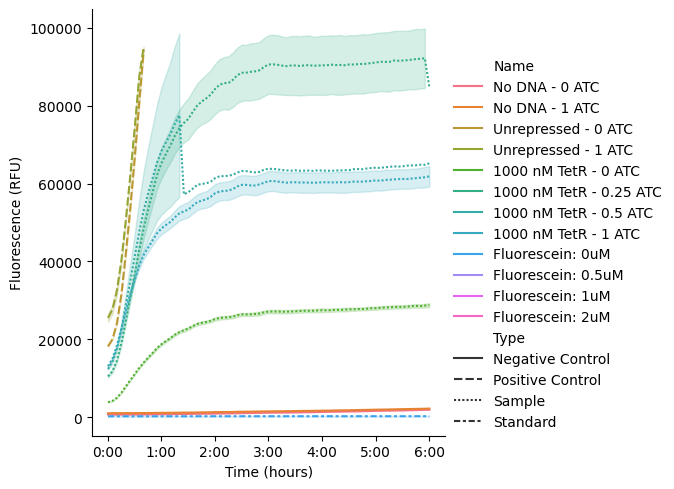

In [ ]:
data.plot(style='Type')

We can see that the standard (here, HPTS) is stable and can be safely used for normalization.

## Normalize Data
Now, use `data.normalize('<standard name>')` to normalize your data. This will calculate the average over a time window at the end of the experiment (by default, 1 hour), then divide all data by the mean of that window-average across all wells with the same `Name` (defined by your platemap).

In [ ]:
# To check the exact name of your standard
platemap = data.platemap
standards = platemap[platemap['Type']=='Standard']
standards['Name'].unique()

array(['10 uM HPTS'], dtype=object)

In [ ]:
data = data.normalize('10 uM HPTS')

Now replot your curves to see them normalized:

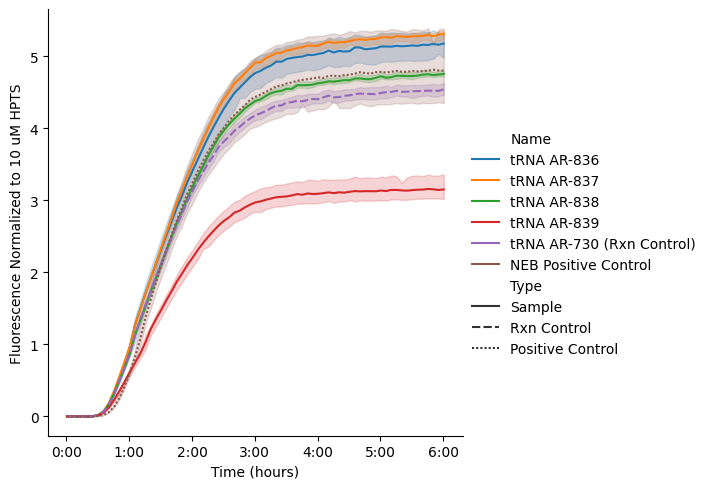

In [ ]:
g = data.plot(style='Type', exclude_types=['Standard'])
# g.savefig('after-normalization.png',dpi=300)

If you want to change the time window over which you calculate the average, you can use the `window` argument:

In [ ]:
# data = data.normalize('10 uM HPTS', window=pd.Timedelta("2.5h"))

## Kinetic Analysis

See the [DevNote](https://devnotes.nucleus.engineering/articles/Newman-20260421) on kinetic analysis for more details.

**Metrics extracted:**

  - **Maximum velocity**: Maximum rate of fluorescence increase (slope at inflection point)
  - **Lag time**: Time to reach the exponential phase
  - **Steady-state**: Final fluorescence level
  - **Time-to-completion**: Time it takes to reach 95% of asymptote
  - **Drift**: Rate of signal decay or increase after steady-state
  - **R²**: Goodness of fit; "Good Fit" is `True` if $R^2 \geq 0.95$

In [ ]:
# Perform kinetic analysis using sigmoid_drift model
kinetics = data.fit_kinetics()

In [ ]:
kinetics.summary

,Well,Name,Max Velocity,Max Velocity Time,Lag Time,Steady State,Completion Time,Completion Threshold,Drift,Fit Function,R^2,Good Fit
0,B2,No DNA - 0 ATC,329.61,0 days 06:00:11,-1 days +23:15:55,4219.50,0 days 15:55:21,0.95,-52.53,sigmoid_drift,1.00,True
1,B3,No DNA - 0 ATC,309.76,0 days 06:00:11,-1 days +23:33:33,3792.43,0 days 15:29:23,0.95,-34.99,sigmoid_drift,1.00,True
2,C2,No DNA - 1 ATC,317.78,0 days 06:00:11,-1 days +22:57:29,4253.67,0 days 16:22:30,0.95,-53.70,sigmoid_drift,1.00,True
3,C3,No DNA - 1 ATC,290.97,0 days 06:00:11,-1 days +22:42:38,4031.66,0 days 16:44:21,0.95,-48.78,sigmoid_drift,1.00,True
4,D2,Unrepressed - 0 ATC,196110.94,0 days 00:27:33,0 days 00:10:28,106139.30,0 days 00:52:43,0.95,-22183.75,sigmoid_drift,1.00,True
5,D3,Unrepressed - 0 ATC,201118.76,0 days 00:27:35,0 days 00:10:40,107768.64,0 days 00:52:30,0.95,-22194.79,sigmoid_drift,1.00,True
6,E2,Unrepressed - 1 ATC,200129.02,0 days 00:25:29,0 days 00:07:52,111700.89,0 days 00:51:26,0.95,-32109.22,sigmoid_drift,1.00,True
7,E3,Unrepressed - 1 ATC,173940.51,0 days 00:27:05,0 days 00:06:11,115113.17,0 days 00:57:51,0.95,-27186.16,sigmoid_drift,1.00,True
8,F2,1000 nM TetR - 0 ATC,15884.62,0 days 00:29:52,-1 days +23:36:32,26825.29,0 days 01:48:23,0.95,630.68,sigmoid_drift,1.00,True
9,F3,1000 nM TetR - 0 ATC,16494.61,0 days 00:29:37,-1 days +23:36:28,27763.73,0 days 01:47:53,0.95,667.52,sigmoid_drift,1.00,True


## Visualize Fits

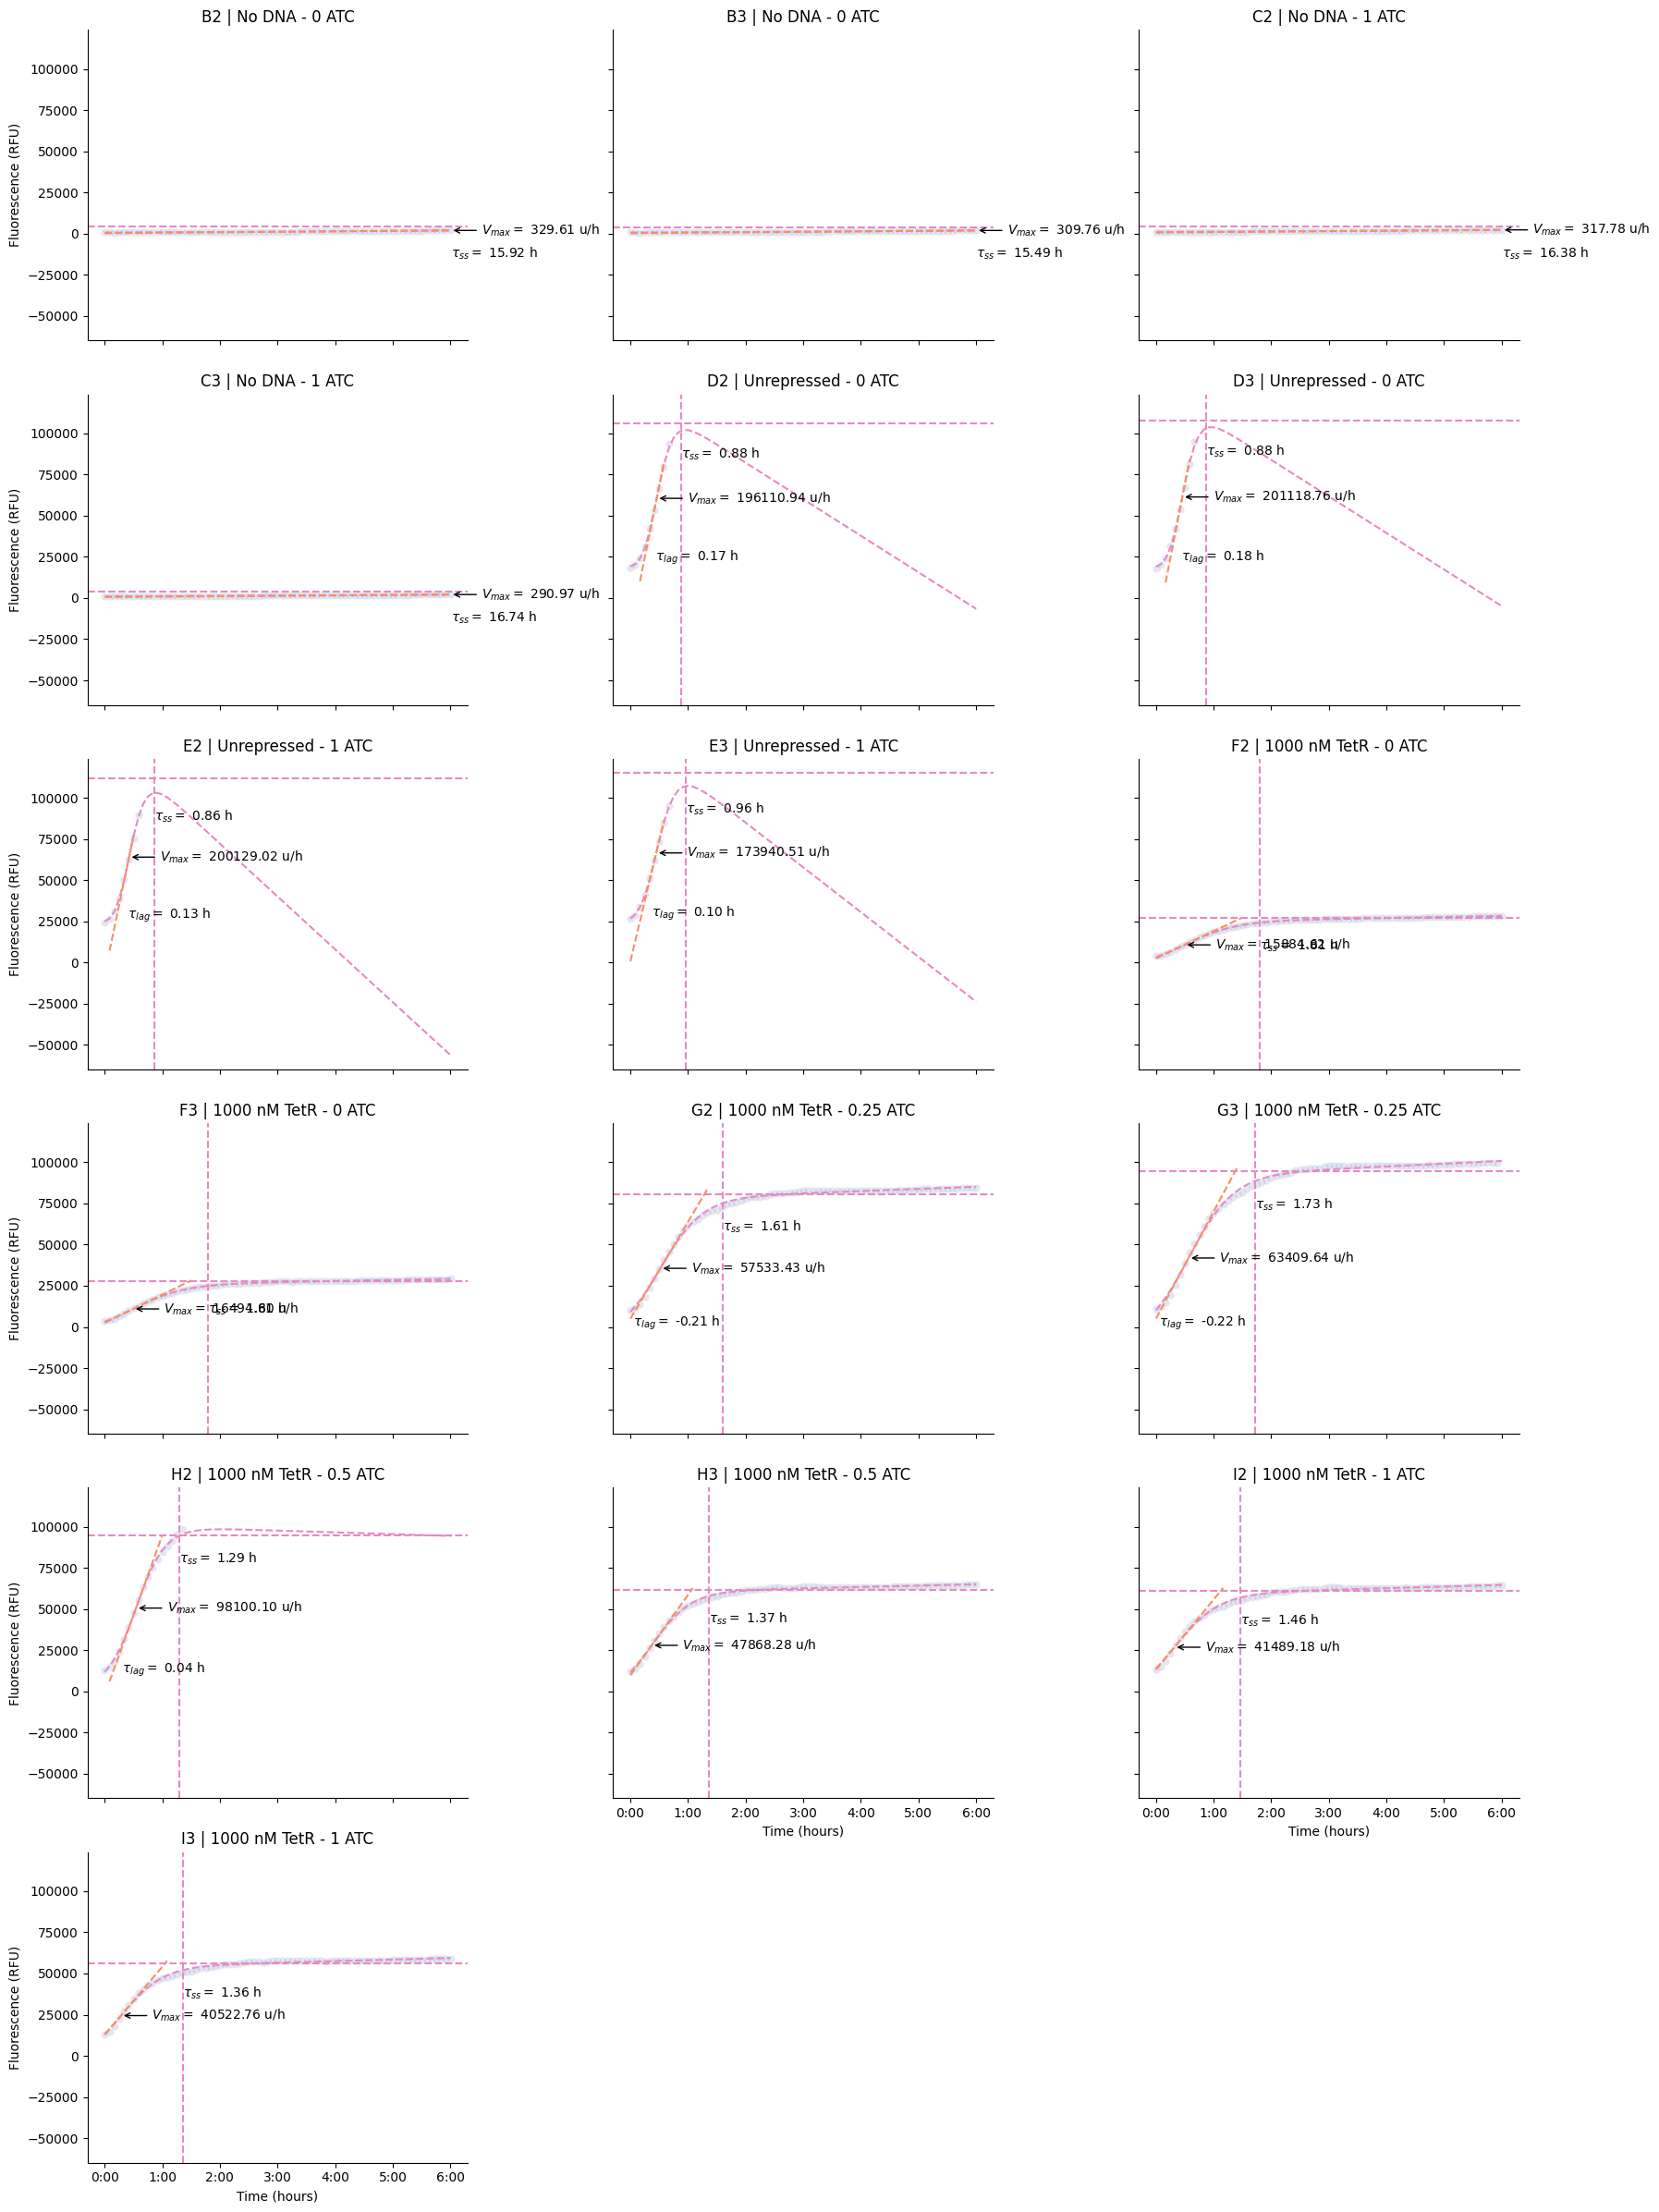

In [ ]:
g = kinetics.plot(col="Well")
# g = kinetics.plot() # call this to visualize across replicates

## Summary Plots

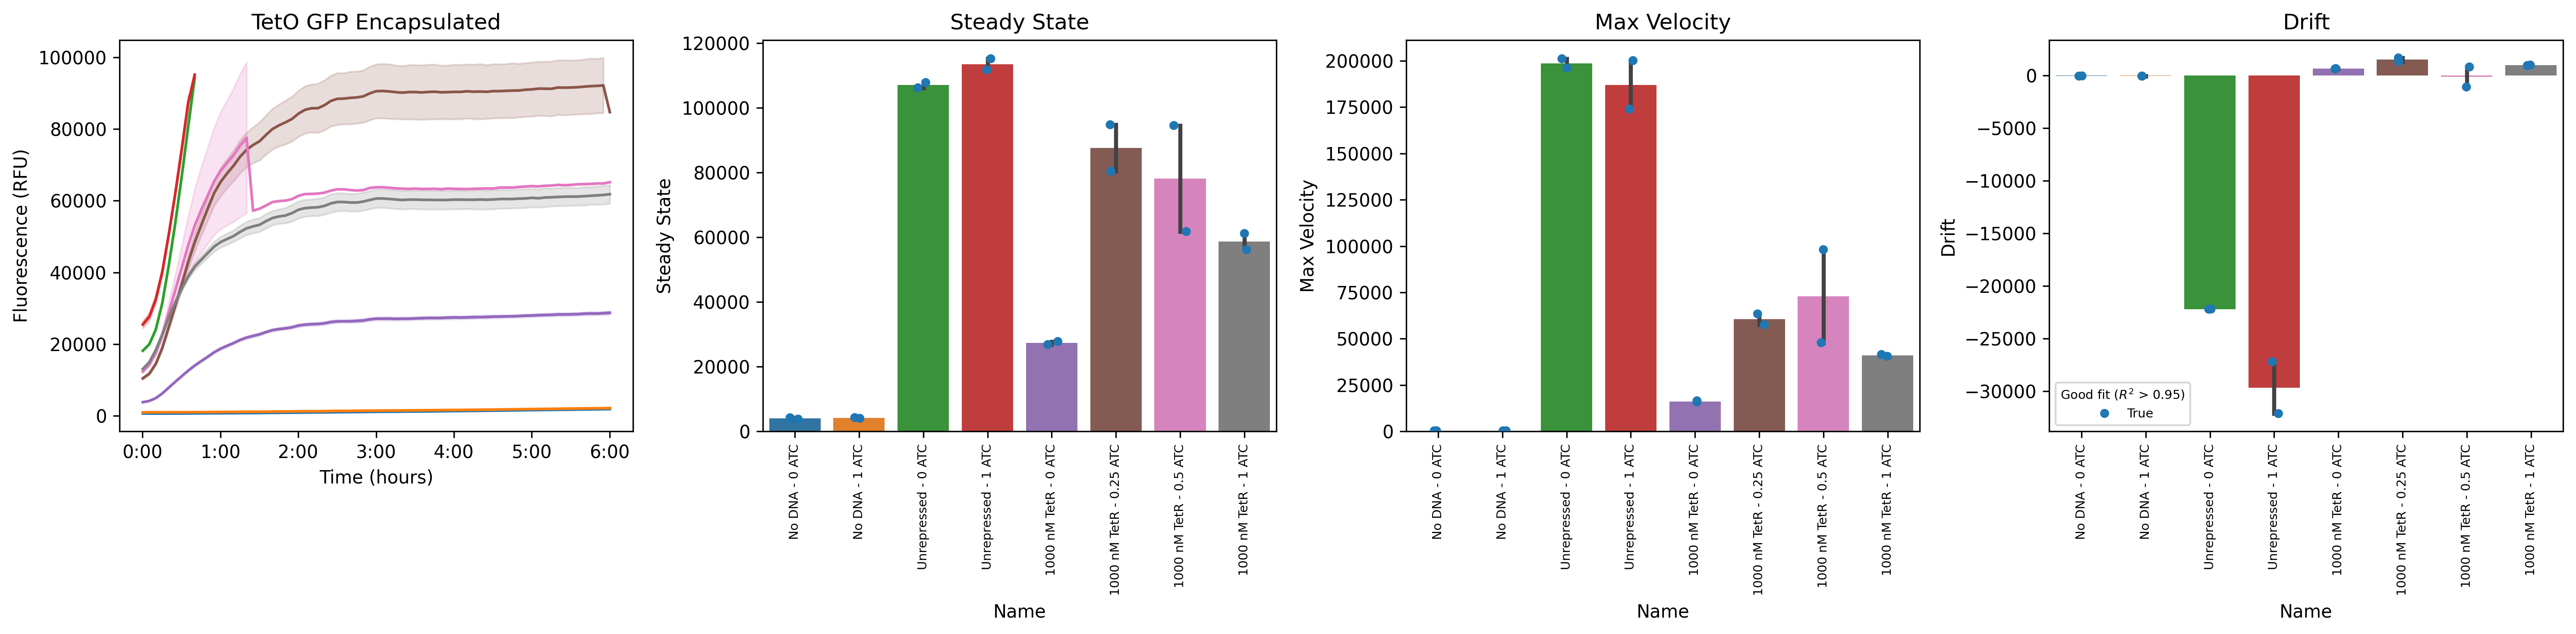

In [ ]:
#| label: mk-20260928
g = kinetics.plot_summary()

---

## Key Metrics Explained

### 1. **Steady-State Level** (`Steady State, Data`)
- The final fluorescence value reached by the reaction
- Represents the total amount of protein produced
- Higher values indicate greater expression yield

### 2. **Maximum Velocity** (`Velocity, Max`)
- The steepest slope of the fluorescence curve (at the inflection point)
- Units: RFU per second
- Reflects the peak rate of protein synthesis
- Sensitive to enzyme activity, substrate availability, and reaction conditions

### 3. **Lag Time** (`Lag, Time`)
- Time before exponential fluorescence increase begins
- May reflect time for ribosome assembly or initial translation steps
- Shorter lag times suggest faster reaction initiation

### 4. **Drift** (`Fit, drift`)
- Rate of fluorescence change after reaching steady-state
- Positive drift: continued synthesis or aggregation
- Negative drift: photobleaching, protein degradation, or quenching
- Units: RFU per second

### 5. **R² Value** (`Fit, R^2`)
- Goodness of fit (0 to 1, higher is better)
- R² > 0.98 indicates excellent fit
- Poor fits may indicate noisy data, overflow errors, or non-sigmoid kinetics

---

## Tips and Troubleshooting

- **Overflow errors:** Wells with `OVRFLW` or `NaN` values are automatically excluded from fitting
- **Poor fits (low R²):** Inspect raw curves for anomalies (bubbles, evaporation, pipetting errors)
- **Drift:** Sometimes seen in kinetics curves; use `sigmoid_drift` model
- **Multiple replicates:** Always include technical replicates and report error bars
- **Comparing conditions:** Normalize or blank data consistently across all samples

---

## Next Steps

- Export kinetics results: `pr.export_kinetics(kinetics, 'results.csv')`
- Statistical analysis: Use `scipy.stats` or `statsmodels` for ANOVA/t-tests
- Parameter optimization: Vary Mg²⁺, K⁺, or other conditions to maximize Vmax or steady-state
- Mechanistic modeling: Fit ODE models to extract biological rate constants